# Quantum Neural Network for Intraday Signal Generation
**Hybrid quantum-classical prototype (Qiskit)** - predicts next-minute price direction (UP / DOWN) and emits a BUY / SELL signal.

**Pipeline:** market data → features → amplitude encoding (4 qubits) → variational circuit → ⟨Z⟩ → probability → signal

> Proof of concept for learning and research. Not financial advice, not a validated trading strategy.

Install (once): `pip install qiskit matplotlib scikit-learn pylatexenc` (for TradingView data: `pip install --upgrade git+https://github.com/rongardF/tvdatafeed.git` and `pip install tradingview_ta`)

## 1. Setup and configuration

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from sklearn.linear_model import LogisticRegression

SEED = 7
rng = np.random.default_rng(SEED)

N_QUBITS = 4
N_AMPS = 2 ** N_QUBITS      # 16 amplitudes -> 4 features padded with zeros
DEPTH = 3                   # variational layers
N_EPOCHS = 40
LEARNING_RATE = 0.1

## 2. Data (TradingView)
Historical 1-minute bars for **RPOWER (NSE)** are pulled from TradingView using the unofficial `tvdatafeed` package:
`pip install --upgrade git+https://github.com/rongardF/tvdatafeed.git`

`DATA_SOURCE` options:
- `"tradingview"`: download bars directly (no login needed for basic data, but TradingView may rate-limit)
- `"csv"`: use a file exported from TradingView (chart menu → *Export chart data*); needs `close` and `volume` columns
- `"simulated"`: offline synthetic series

If the chosen source fails, the notebook falls back to the simulated series and prints a warning.

Source: simulated | bars: 1500 | last close: 1,491.42


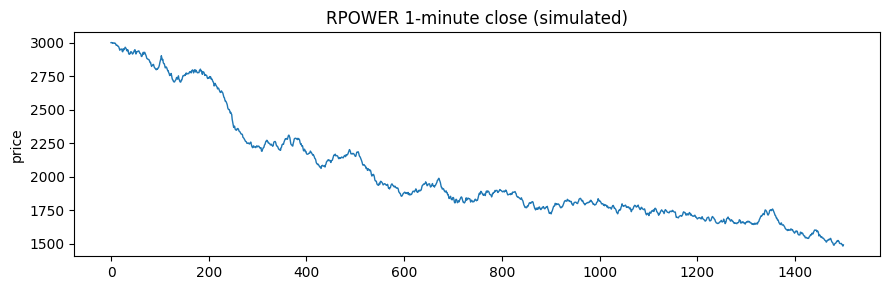

In [2]:
DATA_SOURCE = "tradingview"      # "tradingview" | "csv" | "simulated"
SYMBOL, EXCHANGE = "RPOWER", "NSE"
N_BARS = 5000                    # TradingView allows up to 5000 bars per request
CSV_PATH = None                  # e.g. "NSE_RPOWER, 1.csv"

def load_tradingview(symbol, exchange, n_bars):
    from tvDatafeed import TvDatafeed, Interval
    tv = TvDatafeed()            # anonymous session
    df = tv.get_hist(symbol=symbol, exchange=exchange, interval=Interval.in_1_minute, n_bars=n_bars)
    if df is None or df.empty:
        raise RuntimeError("TradingView returned no data (check symbol/exchange or retry later)")
    return df

def load_csv(path):
    import pandas as pd
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    return df

def simulate_market(n=1500, p0=3000.0):
    # Fallback: weak AR(1) momentum with stochastic volatility
    ret = np.zeros(n); vol = np.zeros(n); vol[0] = 0.0008
    for t in range(1, n):
        vol[t] = 0.9 * vol[t-1] + 0.1 * 0.0008 + 0.0004 * abs(rng.normal())
        ret[t] = 0.25 * ret[t-1] + vol[t] * rng.normal()
    price = p0 * np.exp(np.cumsum(ret))
    volume = 1e6 * (1 + 20 * vol / 0.0008 * 0.1) * rng.lognormal(0, 0.3, n)
    return price, volume

index, source_used = None, DATA_SOURCE
try:
    if DATA_SOURCE == "tradingview":
        df = load_tradingview(SYMBOL, EXCHANGE, N_BARS)
    elif DATA_SOURCE == "csv":
        df = load_csv(CSV_PATH)
    else:
        raise ValueError("simulated requested")
    df = df.dropna(subset=["close"])
    price, volume = df["close"].to_numpy(float), df["volume"].to_numpy(float)
    index = df.index if DATA_SOURCE == "tradingview" else None
except Exception as e:
    if DATA_SOURCE != "simulated":
        print(f"WARNING: could not load '{DATA_SOURCE}' data ({e}). Falling back to simulated data.")
    price, volume = simulate_market()
    source_used = "simulated"

print(f"Source: {source_used} | bars: {len(price)} | last close: {price[-1]:,.2f}")

plt.figure(figsize=(9, 3))
plt.plot(index if index is not None else np.arange(len(price)), price, lw=1)
plt.title(f"{SYMBOL} 1-minute close ({source_used})"); plt.ylabel("price"); plt.tight_layout(); plt.show()

## 3. Feature engineering
Four features, computed **only from past data** (no look-ahead):
1. last 1-minute return, 2. rolling volatility (10 bars), 3. RSI (14 bars), 4. volume z-score (20 bars).
Label = 1 if the **next** close is higher than the current close.

In [3]:
def rsi(p, n=14):
    d = np.diff(p, prepend=p[0])
    up, dn = np.clip(d, 0, None), np.clip(-d, 0, None)
    out = np.full(len(p), 50.0)
    for t in range(n, len(p)):
        u, v = up[t-n+1:t+1].mean(), dn[t-n+1:t+1].mean()
        out[t] = 100 - 100 / (1 + u / (v + 1e-12))
    return out

def make_features(price, volume):
    ret = np.diff(np.log(price), prepend=np.log(price[0]))
    vola = np.array([ret[max(0, t-9):t+1].std() for t in range(len(ret))])
    r = rsi(price)
    vz = np.array([(volume[t] - volume[max(0, t-19):t+1].mean()) /
                   (volume[max(0, t-19):t+1].std() + 1e-9) for t in range(len(volume))])
    return np.column_stack([ret, vola, r, vz])

F = make_features(price, volume)[:-1]                 # drop last row (no next price)
y = (price[1:] > price[:-1]).astype(int)              # next-bar direction
start = 30                                            # warm-up for rolling indicators
F, y = F[start:], y[start:]

split = int(0.7 * len(F))                             # chronological split (no shuffling)
F_tr, F_te, y_tr, y_te = F[:split], F[split:], y[:split], y[split:]
mu, sd = F_tr.mean(0), F_tr.std(0) + 1e-9             # statistics from TRAIN only

def amplitude_encode(feats):
    z = (feats - mu) / sd
    padded = np.pad(z, ((0, 0), (0, N_AMPS - z.shape[1])))
    n = np.linalg.norm(padded, axis=1, keepdims=True)
    return (padded / np.where(n == 0, 1, n)).astype(complex)

X_tr, X_te = amplitude_encode(F_tr), amplitude_encode(F_te)
print(f"train {X_tr.shape}, test {X_te.shape}, class balance (up) train={y_tr.mean():.2f} test={y_te.mean():.2f}")

train (1028, 16), test (441, 16), class balance (up) train=0.45 test=0.47


## 4. The quantum circuit
- **Encoding:** amplitude embedding - 16 normalised amplitudes become the 4-qubit state.
- **Ansatz:** `DEPTH` layers of RY rotations on each qubit followed by a ring of CNOTs (entanglement).
- **Readout:** expectation ⟨Z⟩ on one qubit, mapped to a probability `p = (⟨Z⟩ + 1) / 2`.

Qiskit is little-endian, so a helper maps the "wire 0 = first qubit" convention to the right Qiskit index.

Qubits: 4 | trainable parameters: 12 | depth: 15


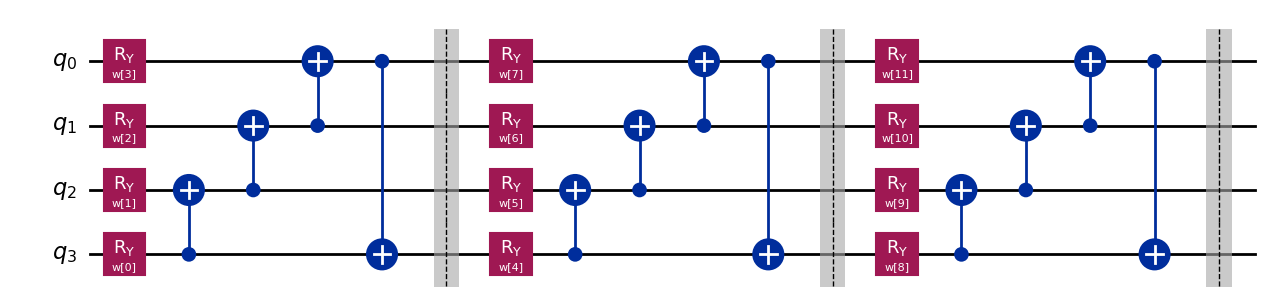

In [4]:
def q(wire):                       # wire 0 (most significant) -> Qiskit qubit index
    return N_QUBITS - 1 - wire

theta = ParameterVector("w", DEPTH * N_QUBITS)
ansatz = QuantumCircuit(N_QUBITS)
k = 0
for layer in range(DEPTH):
    for i in range(N_QUBITS):
        ansatz.ry(theta[k], q(i)); k += 1
    for i in range(N_QUBITS - 1):
        ansatz.cx(q(i), q(i + 1))
    ansatz.cx(q(N_QUBITS - 1), q(0))
    ansatz.barrier()

observable = SparsePauliOp("".join("Z" if kk == q(0) else "I" for kk in reversed(range(N_QUBITS))))
print(f"Qubits: {N_QUBITS} | trainable parameters: {len(theta)} | depth: {ansatz.depth()}")
ansatz.draw("mpl", fold=-1)

### Fast batched evaluation
For speed, we build the circuit's unitary once per weight vector and apply it to *all* encoded states at once. A check below confirms this matches Qiskit's `Statevector` simulation exactly.

In [5]:
z_diag = np.real(np.diag(observable.to_matrix()))      # diagonal of the Z observable

def expectations(X, w):
    U = Operator(ansatz.assign_parameters(np.asarray(w).flatten())).data
    out = X @ U.T                                        # evolve every state
    return (np.abs(out) ** 2) @ z_diag                   # <Z> for every sample

# sanity check against Qiskit Statevector
w0 = rng.uniform(-np.pi, np.pi, DEPTH * N_QUBITS)
sv = Statevector(X_tr[0]).evolve(ansatz.assign_parameters(w0)).expectation_value(observable).real
print("Statevector:", round(sv, 8), "| batched:", round(expectations(X_tr[:1], w0)[0], 8))

Statevector: 0.43742249 | batched: 0.43742249


## 5. Training
Loss: binary cross-entropy. Gradients: **parameter-shift rule** (exact for RY gates). Optimiser: Adam (implemented from scratch).

In [6]:
def predict_proba(X, w):
    return (expectations(X, w) + 1) / 2

def bce(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.mean(-y * np.log(p) - (1 - y) * np.log(1 - p))

def grad(w, X, y):
    w = np.asarray(w, float); g = np.zeros_like(w); s = np.pi / 2
    p = np.clip(predict_proba(X, w), 1e-6, 1 - 1e-6)
    dldp = (-y / p + (1 - y) / (1 - p))
    for k in range(len(w)):
        wp, wm = w.copy(), w.copy(); wp[k] += s; wm[k] -= s
        de = (expectations(X, wp) - expectations(X, wm)) / 2   # d<Z>/dw_k
        g[k] = np.mean(dldp * 0.5 * de)
    return g

class Adam:
    def __init__(self, lr=0.1, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.m, self.v, self.t = lr, b1, b2, eps, 0, 0, 0
    def step(self, w, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g * g
        a = self.lr * np.sqrt(1 - self.b2 ** self.t) / (1 - self.b1 ** self.t)
        return w - a * self.m / (np.sqrt(self.v) + self.eps)

w = rng.normal(0, np.pi, DEPTH * N_QUBITS)
opt = Adam(LEARNING_RATE)
train_loss, test_loss, train_acc, test_acc = [], [], [], []
acc = lambda p, y: np.mean((p > 0.5) == y)

for epoch in range(N_EPOCHS):
    w = opt.step(w, grad(w, X_tr, y_tr))
    ptr, pte = predict_proba(X_tr, w), predict_proba(X_te, w)
    train_loss.append(bce(ptr, y_tr)); test_loss.append(bce(pte, y_te))
    train_acc.append(acc(ptr, y_tr));  test_acc.append(acc(pte, y_te))
    if epoch % 5 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:2d} | loss {train_loss[-1]:.4f} | train acc {train_acc[-1]:.3f} | test acc {test_acc[-1]:.3f}")

epoch  0 | loss 0.7683 | train acc 0.461 | test acc 0.472


epoch  5 | loss 0.6921 | train acc 0.538 | test acc 0.526


epoch 10 | loss 0.6939 | train acc 0.522 | test acc 0.501


epoch 15 | loss 0.6855 | train acc 0.536 | test acc 0.506


epoch 20 | loss 0.6856 | train acc 0.549 | test acc 0.526


epoch 25 | loss 0.6846 | train acc 0.558 | test acc 0.556


epoch 30 | loss 0.6828 | train acc 0.559 | test acc 0.558


epoch 35 | loss 0.6822 | train acc 0.552 | test acc 0.560
epoch 39 | loss 0.6817 | train acc 0.550 | test acc 0.551


## 6. Results

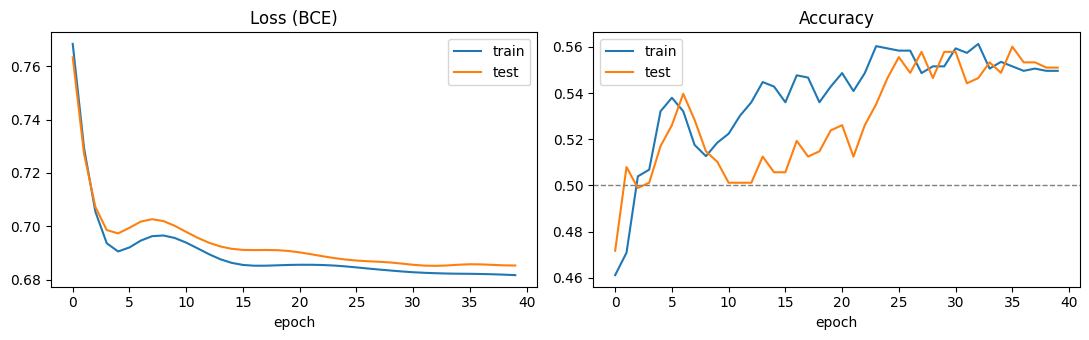

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(train_loss, label="train"); ax[0].plot(test_loss, label="test")
ax[0].set_title("Loss (BCE)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(train_acc, label="train"); ax[1].plot(test_acc, label="test")
ax[1].axhline(0.5, color="gray", ls="--", lw=1); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### Classical baseline and a simple backtest
A quantum model is only interesting if we compare it against a classical one on the same features and split. The backtest is deliberately simple: go long when BUY, short when SELL, one bar ahead, **no costs**.

Majority-class baseline : 0.533
Logistic regression     : 0.590
Quantum NN (4 qubits)   : 0.551
Strategy total log return (no costs): 0.2729 | buy & hold: -0.1731
Note: simulated data and no transaction costs - treat this as a pipeline check, not evidence of an edge.


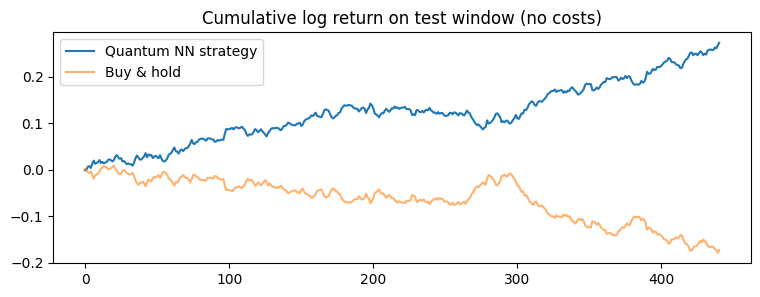

In [8]:
# Classical baseline on the same normalised features
lr = LogisticRegression().fit((F_tr - mu) / sd, y_tr)
base_acc = lr.score((F_te - mu) / sd, y_te)

p_te = predict_proba(X_te, w)
q_acc = acc(p_te, y_te)
majority = max(y_te.mean(), 1 - y_te.mean())

# Backtest on the test window
rets = np.diff(np.log(price))[start:][split:]            # next-bar log returns aligned with test rows
pos = np.where(p_te > 0.5, 1, -1)
strat = pos * rets

print(f"Majority-class baseline : {majority:.3f}")
print(f"Logistic regression     : {base_acc:.3f}")
print(f"Quantum NN (4 qubits)   : {q_acc:.3f}")
print(f"Strategy total log return (no costs): {strat.sum():.4f} | buy & hold: {rets.sum():.4f}")
print("Note: simulated data and no transaction costs - treat this as a pipeline check, not evidence of an edge.")

plt.figure(figsize=(9, 3))
plt.plot(np.cumsum(strat), label="Quantum NN strategy"); plt.plot(np.cumsum(rets), label="Buy & hold", alpha=.6)
plt.title("Cumulative log return on test window (no costs)"); plt.legend(); plt.show()

## 7. Live signal mode (optional)
Uses `tradingview_ta` for live 1-minute data on NSE (`RPOWER`). If the library or network is unavailable, it **falls back to simulated ticks** so the demo always runs.
The live features use the **same training normalisation** (`mu`, `sd`). TradingView's snapshot doesn't give our exact return/volatility features, so it is approximated and clearly a demo.

In [9]:
LIVE_STEPS = 5          # number of iterations to demo
SLEEP_SECONDS = 2       # use 60 for real 1-minute polling

def get_live_row(prev_price, prev_vol_hist):
    try:
        from tradingview_ta import TA_Handler, Interval
        h = TA_Handler(symbol="RPOWER", screener="india", exchange="NSE", interval=Interval.INTERVAL_1_MINUTE)
        ind = h.get_analysis().indicators
        p, v, r = ind["close"], ind.get("volume", 1e6), ind.get("RSI", 50)
        src = "live"
    except Exception:
        p = prev_price * np.exp(rng.normal(0, 0.0008)); v = 1e6 * rng.lognormal(0, 0.3); r = 50 + rng.normal(0, 10)
        src = "simulated"
    ret = np.log(p / prev_price)
    prev_vol_hist.append(v)
    vh = np.array(prev_vol_hist[-20:])
    vz = (v - vh.mean()) / (vh.std() + 1e-9) if len(vh) > 2 else 0.0
    vola = abs(ret)
    return p, np.array([[ret, vola, r, vz]]), src

last_price, vol_hist = float(price[-1]), list(volume[-20:])
for _ in range(LIVE_STEPS):
    last_price_new, feats, src = get_live_row(last_price, vol_hist)
    p_up = predict_proba(amplitude_encode(feats), w)[0]
    print(f"[{src}] Price: {last_price_new:,.2f} | P(up): {p_up:.3f} | Signal: {'BUY' if p_up > 0.5 else 'SELL'}")
    last_price = last_price_new
    time.sleep(SLEEP_SECONDS)

[simulated] Price: 1,489.20 | P(up): 0.491 | Signal: SELL


[simulated] Price: 1,488.94 | P(up): 0.479 | Signal: SELL


[simulated] Price: 1,490.05 | P(up): 0.465 | Signal: SELL


[simulated] Price: 1,490.45 | P(up): 0.453 | Signal: SELL


[simulated] Price: 1,492.43 | P(up): 0.448 | Signal: SELL


## 8. Discussion and limitations
- Results on simulated data show the **pipeline works end to end**; they do not prove a real market edge.
- Short-term price direction is very noisy; accuracy near 50-55% is expected, and any claim needs real data, out-of-sample testing and transaction costs.
- Simulation is noiseless (`Statevector`); real hardware adds noise and shot error.
- Amplitude encoding is expensive to prepare on hardware; angle encoding / data re-uploading are natural alternatives.

**Next steps:** real historical 1-minute data, more features (ATR, MACD, order flow), hyper-parameter search, noisy-simulator runs (`qiskit-aer`), and comparison with XGBoost.